In [1]:
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install missingno
!pip install scikit-learn
!conda install openpyxl -y

Jupyter detected...
3 channel Terms of Service accepted
Channels:
 - defaults
Platform: win-64
Solving environment: ...working... done

# All requested packages already installed.





==> WARNING: A newer version of conda exists. <==
    current version: 26.7.3
    latest version: 26.10.0

Please update conda by running

    $ conda self update


WARNING conda.conda_pypi.main:notify_externally_managed_future(156): 
  Did you know? You can install many PyPI packages with conda
  using the conda-pypi beta. Get started:
    https://docs.conda.io/projects/conda/en/stable/new-features.html



In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import MissingIndicator, KNNImputer,SimpleImputer
from sklearn.impute import IterativeImputer

import seaborn as sns

# Identification des valeurs manquantes

In [3]:
# Read the file into dataframes
import pandas as pd
df = pd.read_excel("DATA BI.xlsx",index_col=False,keep_default_na=True,sheet_name='DEPENSES', header=2)
print(df.head())


   N°  Unnamed: 1       DATE  NCG             ICG     NCT   NCG.1  \
0   1           1 2023-01-12  401         FSR AUX  401S02  228300   
1   2           1 2023-01-05  401         FSR AUX  401S02  615002   
2   3           1 2023-01-16  401         FSR AUX  401D02  606200   
3   4           1 2023-01-26  401         FSR AUX  401D01  606100   
4   5           1 2023-01-04  402  SOUS TRAITANTS  402S01  611002   

          N° FCT                                        DESCRIPTION  SODEXO  \
0        23-0013                                      IMPRIMANTE HP     NaN   
1        23-0008                             reparation imprimante      NaN   
2       00001317                             produits bureautiques      NaN   
3             05                                           spot led     NaN   
4  2023BLF/00003  PROJET:- realisation d4un prog de transformati...     NaN   

        HT      TVA   TF       TTC      RS    NET RS  \
0  4150.00  290.500  1.0  4441.500  44.415  4397.085  

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 588 entries, 0 to 587
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   N°           588 non-null    int64         
 1   Unnamed: 1   588 non-null    int64         
 2   DATE         588 non-null    datetime64[us]
 3   NCG          588 non-null    int64         
 4   ICG          588 non-null    str           
 5   NCT          559 non-null    str           
 6   NCG.1        588 non-null    int64         
 7   N° FCT       584 non-null    str           
 8   DESCRIPTION  521 non-null    str           
 9   SODEXO       14 non-null     float64       
 10  HT           586 non-null    float64       
 11  TVA          451 non-null    float64       
 12  TF           422 non-null    float64       
 13  TTC          587 non-null    float64       
 14  RS           135 non-null    float64       
 15  NET RS       417 non-null    float64       
 16  PAIEMENT     582 no

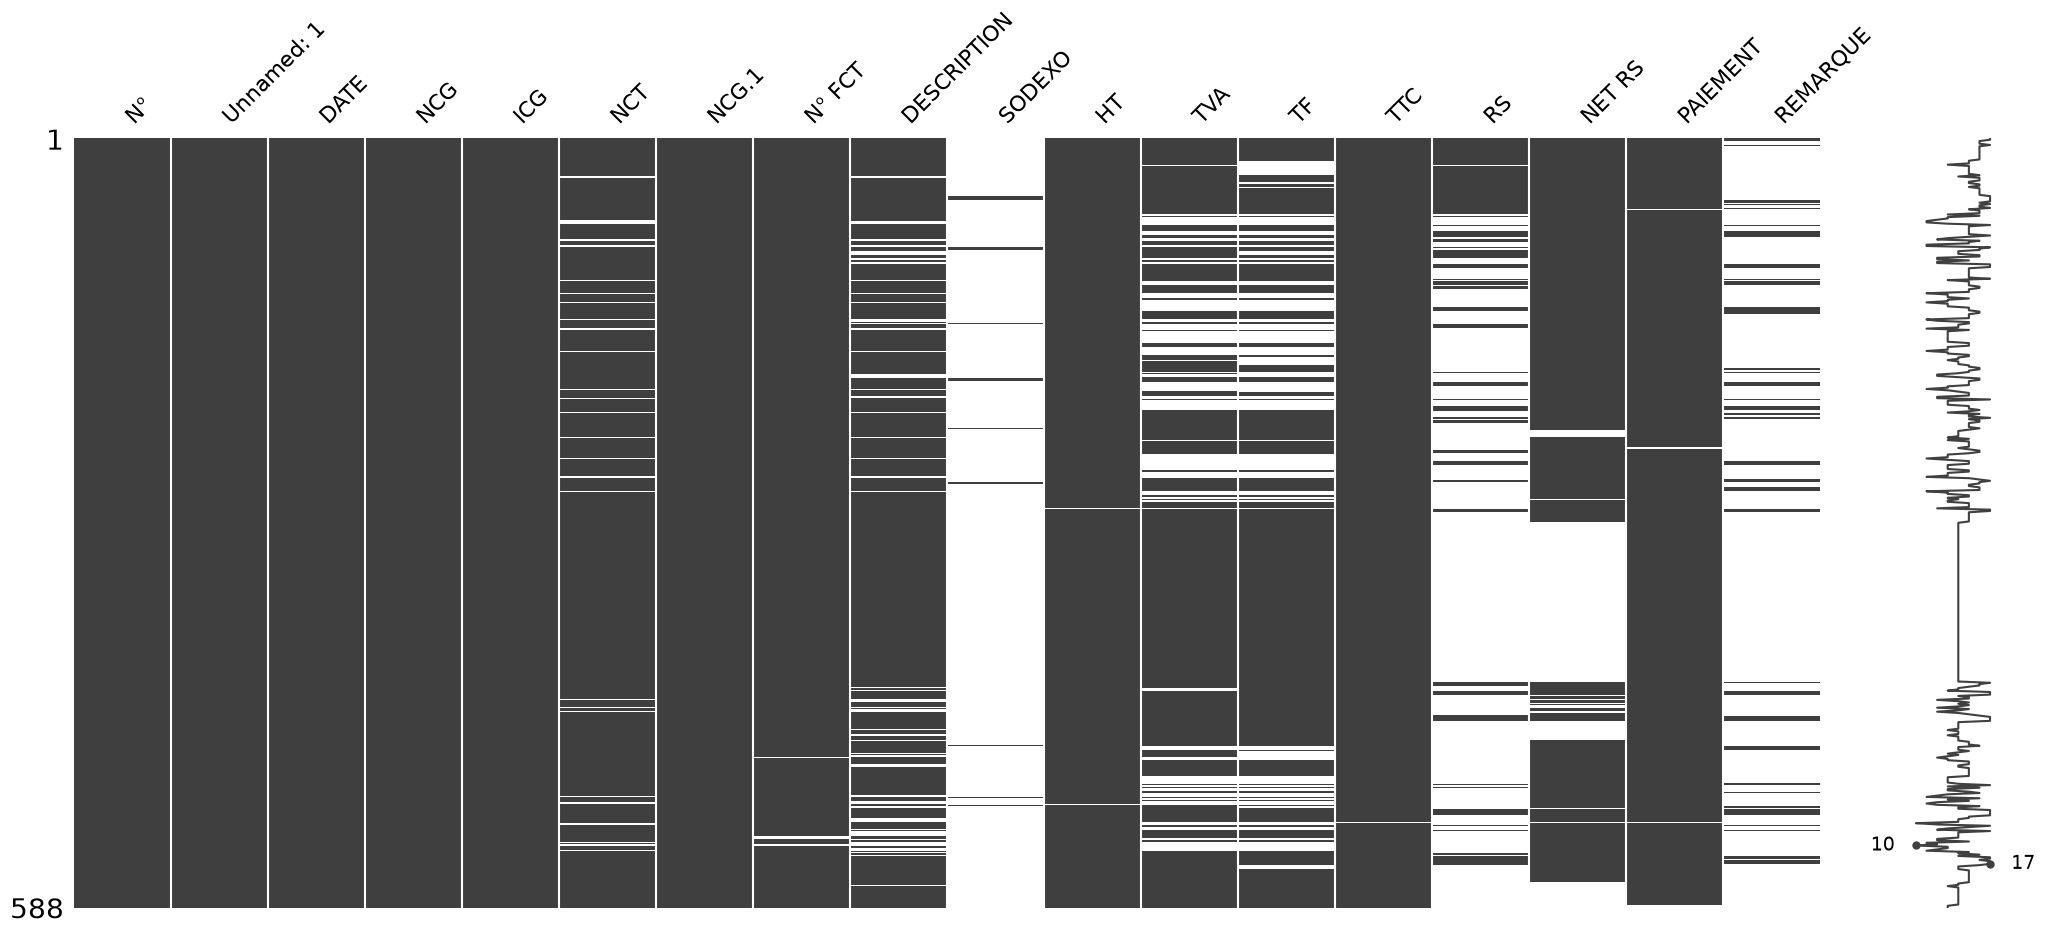

In [5]:
# Visualiser les valeurs manquantes avec missingno
msno.matrix(df)
plt.show()

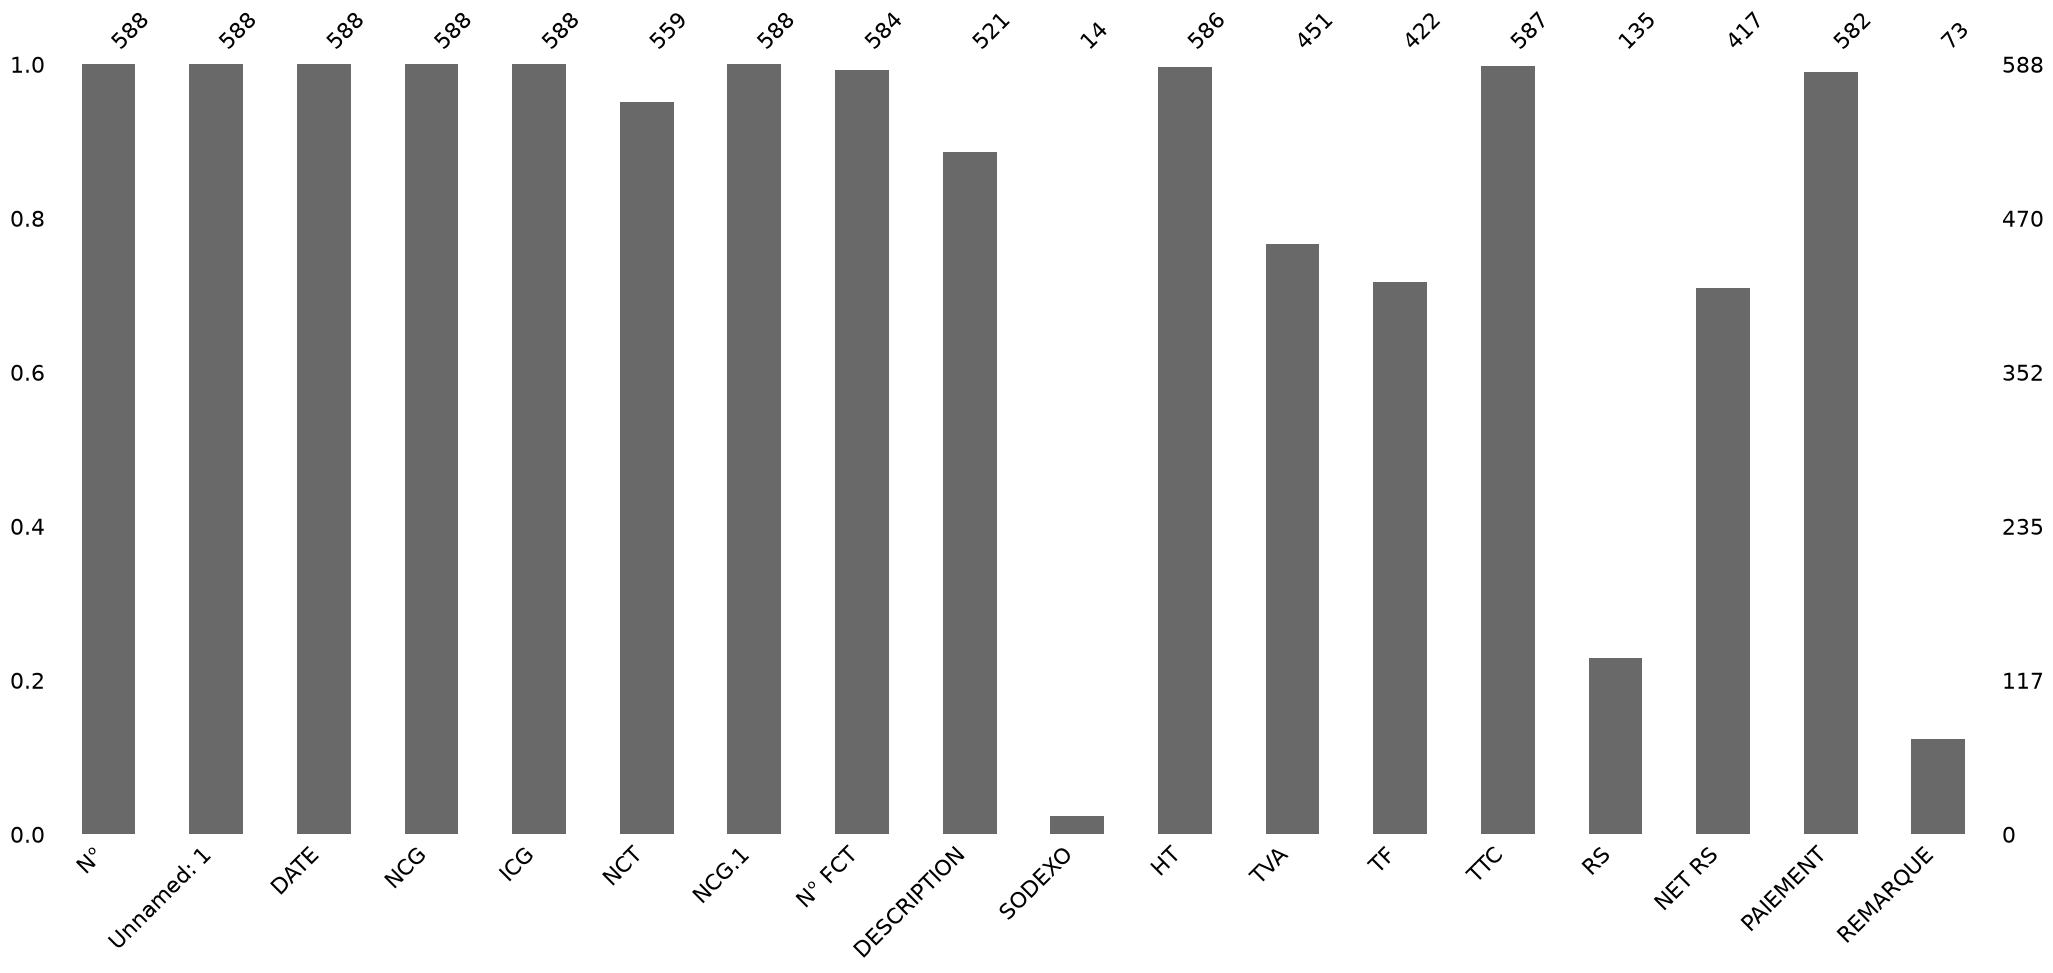

In [6]:
msno.bar(df)
plt.show()

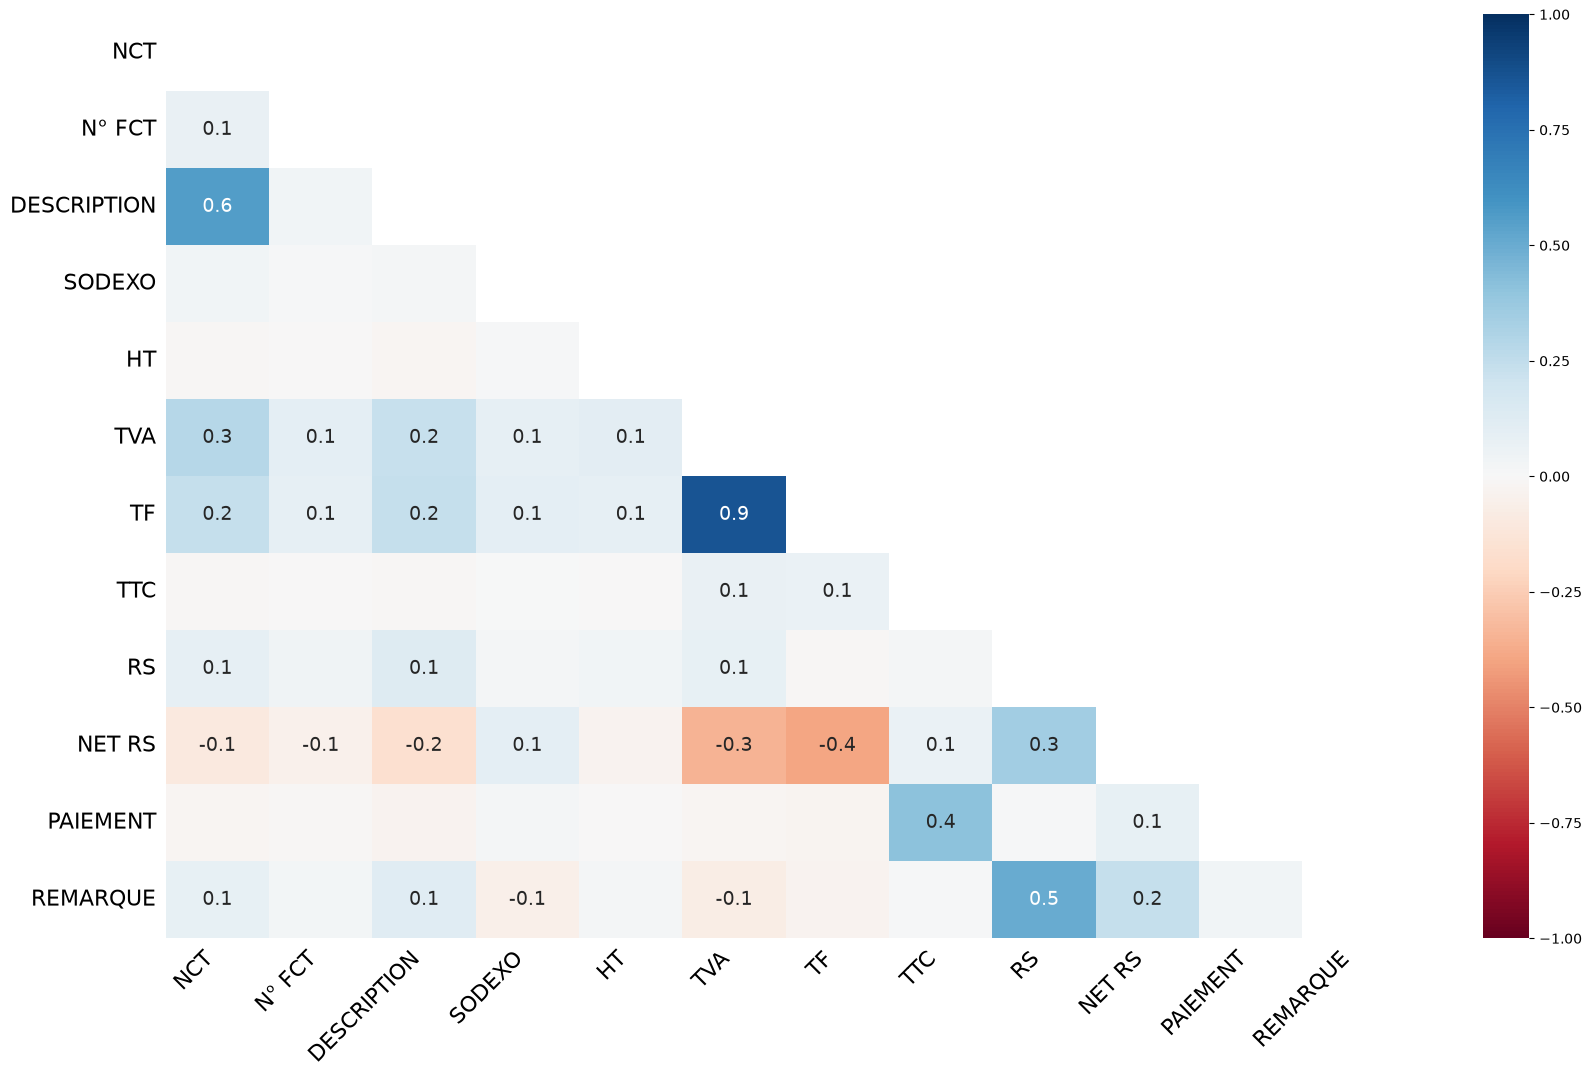

In [7]:
msno.heatmap(df)
plt.show()


In [8]:
# Tableau des valeurs manquantes par colonne
missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100
missing_table = pd.DataFrame({'Missing Values': missing_values, 'Percentage': missing_percent})
print(missing_table)


             Missing Values  Percentage
N°                        0    0.000000
Unnamed: 1                0    0.000000
DATE                      0    0.000000
NCG                       0    0.000000
ICG                       0    0.000000
NCT                      29    4.931973
NCG.1                     0    0.000000
N° FCT                    4    0.680272
DESCRIPTION              67   11.394558
SODEXO                  574   97.619048
HT                        2    0.340136
TVA                     137   23.299320
TF                      166   28.231293
TTC                       1    0.170068
RS                      453   77.040816
NET RS                  171   29.081633
PAIEMENT                  6    1.020408
REMARQUE                515   87.585034


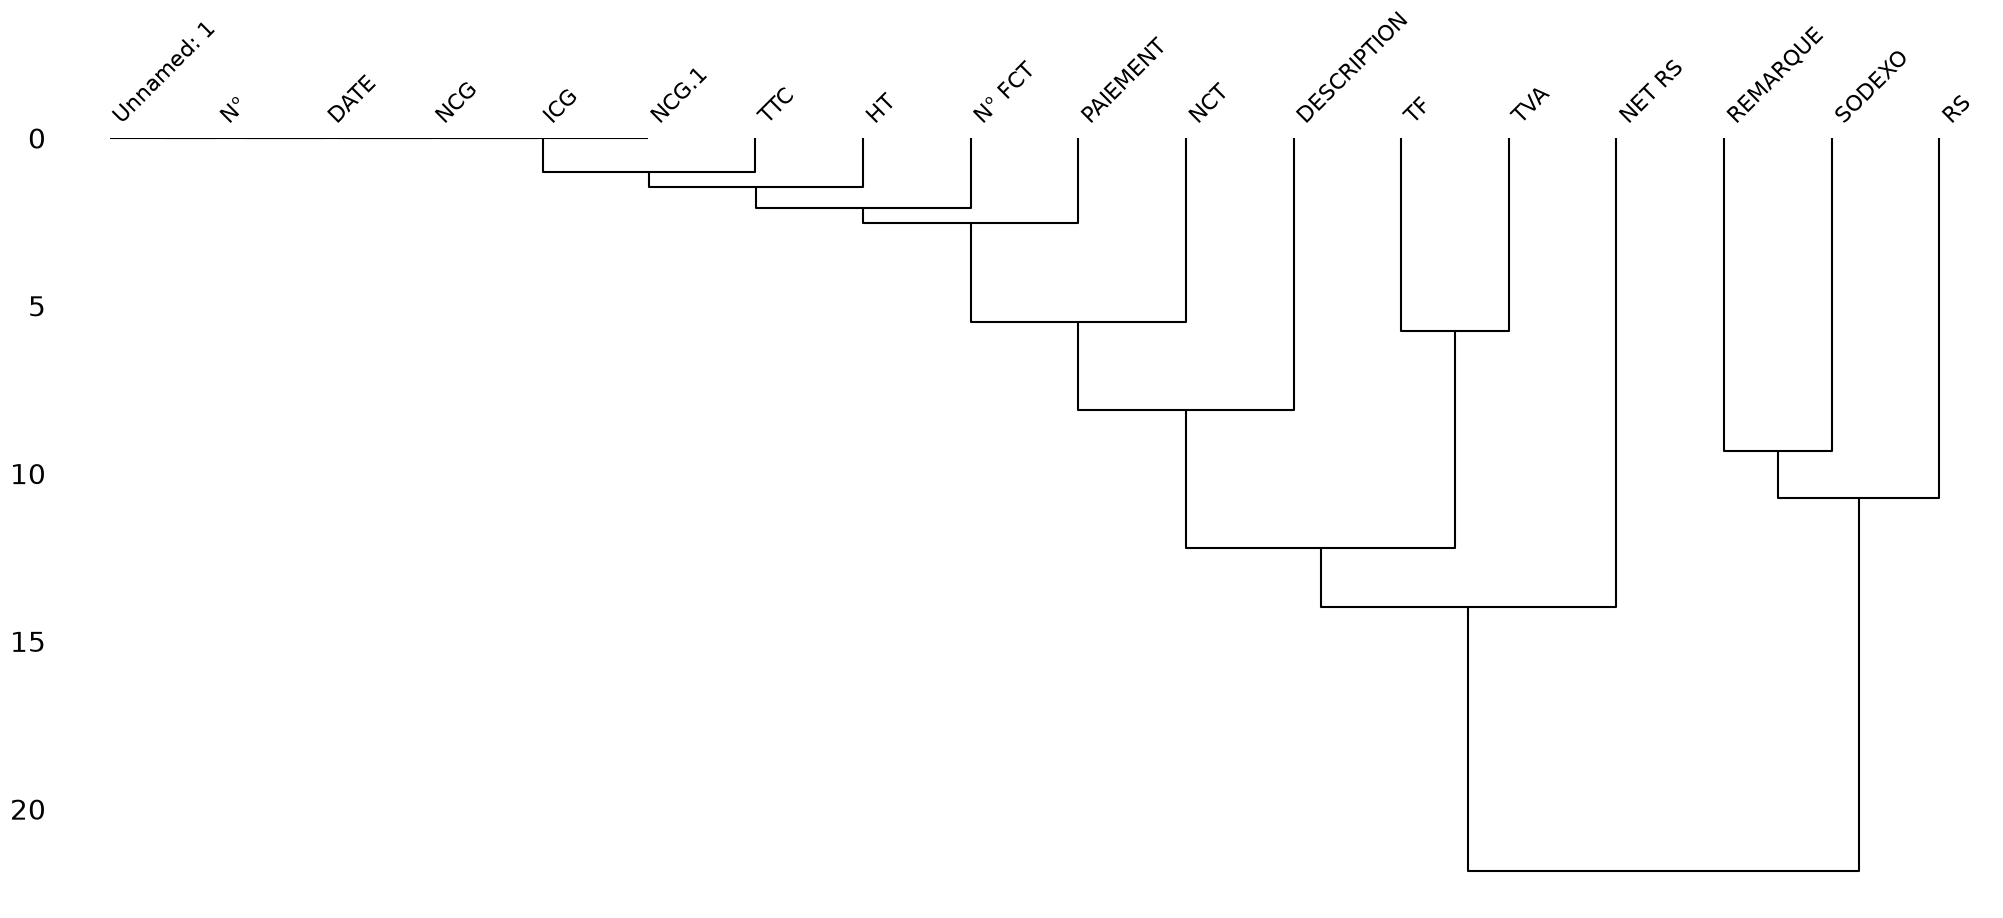

In [9]:
# Analyser la corrélation entre les valeurs manquantes
msno.dendrogram(df)
plt.show()

# Imputation par la médiane, la moyenne et le mode

L'imputation par la moyenne, la médiane et le mode sont des méthodes simples pour remplacer les valeurs manquantes dans une variable.

L'imputation par la moyenne consiste à remplacer les valeurs manquantes par la moyenne des valeurs non manquantes dans la variable. Cette méthode est utile pour les variables continues et symétriques.

L'imputation par la médiane consiste à remplacer les valeurs manquantes par la médiane des valeurs non manquantes dans la variable. Cette méthode est utile pour les variables continues qui ont une distribution asymétrique ou pour les variables ordinales.

L'imputation par le mode consiste à remplacer les valeurs manquantes par le mode, c'est-à-dire la valeur la plus fréquente, dans la variable. Cette méthode est utile pour les variables catégorielles ou nominales.

Ces méthodes sont simples à mettre en œuvre et peuvent être efficaces lorsque les données manquantes sont MCAR (Missing Completely At Random), c'est-à-dire que les valeurs manquantes sont indépendantes des autres variables. Toutefois, elles peuvent introduire un biais dans les données si les valeurs manquantes sont liées à d'autres variables dans les données.

## Imputation par la médiane

In [10]:
imputer_median = SimpleImputer(strategy='median')
df['RS_impute'] = imputer_median.fit_transform(df[['RS']])

df.isnull().mean()

N°             0.000000
Unnamed: 1     0.000000
DATE           0.000000
NCG            0.000000
ICG            0.000000
NCT            0.049320
NCG.1          0.000000
N° FCT         0.006803
DESCRIPTION    0.113946
SODEXO         0.976190
HT             0.003401
TVA            0.232993
TF             0.282313
TTC            0.001701
RS             0.770408
NET RS         0.290816
PAIEMENT       0.010204
REMARQUE       0.875850
RS_impute      0.000000
dtype: float64

In [11]:
# Autre méthode

# Imputation par la médiane pour la colonne 'SODEXO'
median = df['SODEXO'].median()
df['SODEXO_impute']=df['SODEXO'].fillna(median)

# Vérifier les valeurs manquantes après imputation
missing_values_after = df.isnull().mean()
print("\nMissing Values After Treatment:\n", missing_values_after)


Missing Values After Treatment:
 N°               0.000000
Unnamed: 1       0.000000
DATE             0.000000
NCG              0.000000
ICG              0.000000
NCT              0.049320
NCG.1            0.000000
N° FCT           0.006803
DESCRIPTION      0.113946
SODEXO           0.976190
HT               0.003401
TVA              0.232993
TF               0.282313
TTC              0.001701
RS               0.770408
NET RS           0.290816
PAIEMENT         0.010204
REMARQUE         0.875850
RS_impute        0.000000
SODEXO_impute    0.000000
dtype: float64


## Imputation par la moyenne

In [12]:
imputer_mean = SimpleImputer(strategy='mean')
df['RS_imp'] = imputer_mean.fit_transform(df[['RS']])

df.isnull().mean()

N°               0.000000
Unnamed: 1       0.000000
DATE             0.000000
NCG              0.000000
ICG              0.000000
NCT              0.049320
NCG.1            0.000000
N° FCT           0.006803
DESCRIPTION      0.113946
SODEXO           0.976190
HT               0.003401
TVA              0.232993
TF               0.282313
TTC              0.001701
RS               0.770408
NET RS           0.290816
PAIEMENT         0.010204
REMARQUE         0.875850
RS_impute        0.000000
SODEXO_impute    0.000000
RS_imp           0.000000
dtype: float64

In [13]:
# Autre méthode

# Imputation par la moyenne pour la colonne 'total_protein'
mean = df['RS'].mean()
df['RS_impu']=df['RS'].fillna(mean)

# Vérifier les valeurs manquantes après imputation
missing_values_after = df.isnull().mean()
print("\nMissing Values After Treatment:\n", missing_values_after)


Missing Values After Treatment:
 N°               0.000000
Unnamed: 1       0.000000
DATE             0.000000
NCG              0.000000
ICG              0.000000
NCT              0.049320
NCG.1            0.000000
N° FCT           0.006803
DESCRIPTION      0.113946
SODEXO           0.976190
HT               0.003401
TVA              0.232993
TF               0.282313
TTC              0.001701
RS               0.770408
NET RS           0.290816
PAIEMENT         0.010204
REMARQUE         0.875850
RS_impute        0.000000
SODEXO_impute    0.000000
RS_imp           0.000000
RS_impu          0.000000
dtype: float64


## Imputation par le mode

In [14]:
# Imputation par le mode
imputer_mode = SimpleImputer(strategy='most_frequent')
df['RS_imputed'] = imputer_mode.fit_transform(df[['RS']])


In [15]:
# Vérifier les valeurs manquantes après traitement
missing_values = df.isnull().sum()
print("\nMissing Values After Treatment:\n", missing_values)


Missing Values After Treatment:
 N°                 0
Unnamed: 1         0
DATE               0
NCG                0
ICG                0
NCT               29
NCG.1              0
N° FCT             4
DESCRIPTION       67
SODEXO           574
HT                 2
TVA              137
TF               166
TTC                1
RS               453
NET RS           171
PAIEMENT           6
REMARQUE         515
RS_impute          0
SODEXO_impute      0
RS_imp             0
RS_impu            0
RS_imputed         0
dtype: int64


In [16]:
# Autre approche

# imputation par le mode
mode = df['RS'].mode()
df['RS_imputed2'] = df['RS'].fillna(mode)
df.isnull().mean()


N°               0.000000
Unnamed: 1       0.000000
DATE             0.000000
NCG              0.000000
ICG              0.000000
NCT              0.049320
NCG.1            0.000000
N° FCT           0.006803
DESCRIPTION      0.113946
SODEXO           0.976190
HT               0.003401
TVA              0.232993
TF               0.282313
TTC              0.001701
RS               0.770408
NET RS           0.290816
PAIEMENT         0.010204
REMARQUE         0.875850
RS_impute        0.000000
SODEXO_impute    0.000000
RS_imp           0.000000
RS_impu          0.000000
RS_imputed       0.000000
RS_imputed2      0.770408
dtype: float64

# KNN imputer

L'algorithme KNNImputer de scikit-learn est une méthode d'imputation des valeurs manquantes basée sur les k plus proches voisins. Il s'agit d'une approche non-paramétrique qui utilise les valeurs des k plus proches voisins pour imputer les valeurs manquantes.

L'algorithme fonctionne en plusieurs étapes :

1. Définir la valeur de k, qui représente le nombre de voisins les plus proches à considérer pour l'imputation.

2. Pour chaque valeur manquante, trouver les k plus proches voisins parmi les autres observations qui ont des valeurs non manquantes pour la variable en question. La distance entre les observations peut être mesurée de différentes manières, telles que la distance euclidienne ou la distance de Manhattan.

3. Imputer la valeur manquante par la valeur moyenne ou médiane des k voisins les plus proches.

L'algorithme KNNImputer est utile lorsque les données manquantes sont MCAR (Missing Completely At Random) ou MAR (Missing At Random), c'est-à-dire que les valeurs manquantes ne sont pas liées à la valeur de la variable elle-même. Il peut être utilisé pour imputer des variables continues ou catégorielles. Toutefois, il peut être plus lent que d'autres méthodes d'imputation telles que la simple imputation ou l'imputation par la régression.

In [17]:
# Imputation par KNN Imputer
# KNN imputer avec 2 voisins pour plusieurs colonnes
imputer = KNNImputer(n_neighbors=2)

df[['RS_impute_knn', 'SODEXO_knn']] = imputer.fit_transform(df[['RS', 'SODEXO']])

df.isnull().mean()

N°               0.000000
Unnamed: 1       0.000000
DATE             0.000000
NCG              0.000000
ICG              0.000000
NCT              0.049320
NCG.1            0.000000
N° FCT           0.006803
DESCRIPTION      0.113946
SODEXO           0.976190
HT               0.003401
TVA              0.232993
TF               0.282313
TTC              0.001701
RS               0.770408
NET RS           0.290816
PAIEMENT         0.010204
REMARQUE         0.875850
RS_impute        0.000000
SODEXO_impute    0.000000
RS_imp           0.000000
RS_impu          0.000000
RS_imputed       0.000000
RS_imputed2      0.770408
RS_impute_knn    0.000000
SODEXO_knn       0.000000
dtype: float64

# IterativeImputer

L'algorithme IterativeImputer de scikit-learn est une méthode d'imputation des valeurs manquantes basée sur la régression. Il s'agit d'une approche itérative qui utilise un modèle de régression pour imputer les valeurs manquantes à chaque itération, en utilisant les autres variables pour prédire la variable manquante.

L'algorithme fonctionne en plusieurs étapes :

1. Imputer les valeurs manquantes initiales par une stratégie simple comme la moyenne, la médiane ou le mode.

2. Ensuite, le modèle de régression est ajusté pour prédire les valeurs manquantes à partir des autres variables. Cette régression peut être linéaire, non linéaire ou de tout autre type en fonction des données.

3. Les valeurs manquantes sont alors imputées à l'aide du modèle de régression.

4. Les étapes 2 et 3 sont répétées plusieurs fois jusqu'à ce que la convergence soit atteinte. La convergence est déterminée par un critère d'arrêt défini, tel que le nombre maximal d'itérations ou la convergence de la moyenne des différences entre les imputations consécutives.

L'algorithme IterativeImputer est utile lorsque les données manquantes sont MNAR (Missing Not At Random), c'est-à-dire que les valeurs manquantes sont liées à la valeur de la variable elle-même. Il peut être utilisé pour imputer des variables continues ou catégorielles. Toutefois, il peut être plus lent que d'autres méthodes d'imputation telles que la simple imputation.

In [18]:
# Créer un imputer IterativeImputer avec une stratégie de 'mean'
imputer = IterativeImputer(max_iter=10, random_state=0, sample_posterior=True)

df_imputed = pd.DataFrame(imputer.fit_transform(df[['RS', 'SODEXO']]), columns=['RS_imputed', 'SODEXO_imputed'])

# Concaténer la DataFrame imputée avec la DataFrame originale
df = pd.concat([df, df_imputed], axis=1)
df.isnull().mean()

N°                0.000000
Unnamed: 1        0.000000
DATE              0.000000
NCG               0.000000
ICG               0.000000
NCT               0.049320
NCG.1             0.000000
N° FCT            0.006803
DESCRIPTION       0.113946
SODEXO            0.976190
HT                0.003401
TVA               0.232993
TF                0.282313
TTC               0.001701
RS                0.770408
NET RS            0.290816
PAIEMENT          0.010204
REMARQUE          0.875850
RS_impute         0.000000
SODEXO_impute     0.000000
RS_imp            0.000000
RS_impu           0.000000
RS_imputed        0.000000
RS_imputed2       0.770408
RS_impute_knn     0.000000
SODEXO_knn        0.000000
RS_imputed        0.000000
SODEXO_imputed    0.000000
dtype: float64

In [26]:
# Remplacer les valeurs manquantes par une valeur spécifique, par exemple -1
#df_filled = df.fillna(0)

#print(df_filled)
# Remplacer les valeurs manquantes
df_filled = df.copy()

for col in df_filled.columns:
    if pd.api.types.is_numeric_dtype(df_filled[col]):
        df_filled[col] = df_filled[col].fillna(0)
    else:
        df_filled[col] = df_filled[col].fillna("Unknown")

print(df_filled)

Empty DataFrame
Columns: [N°, Unnamed: 1, DATE, NCG, ICG, NCT, NCG.1, N° FCT, DESCRIPTION, SODEXO, HT, TVA, TF, TTC, RS, NET RS, PAIEMENT, REMARQUE, RS_impute, SODEXO_impute, RS_imp, RS_impu, RS_imputed, RS_imputed2, RS_impute_knn, SODEXO_knn, RS_imputed, SODEXO_imputed]
Index: []

[0 rows x 28 columns]


In [25]:
# Supprimer les lignes contenant des valeurs manquantes dans le DataFrame
#df = df.dropna()   (removes a row as soon as it finds at least ONE missing value in any column]


# Supprimer les lignes où la colonne RS contient des valeurs manquantes
df = df.dropna(subset=['RS'])
# Afficher le DataFrame après suppression des lignes avec des valeurs manquantes
print(df)


Empty DataFrame
Columns: [N°, Unnamed: 1, DATE, NCG, ICG, NCT, NCG.1, N° FCT, DESCRIPTION, SODEXO, HT, TVA, TF, TTC, RS, NET RS, PAIEMENT, REMARQUE, RS_impute, SODEXO_impute, RS_imp, RS_impu, RS_imputed, RS_imputed2, RS_impute_knn, SODEXO_knn, RS_imputed, SODEXO_imputed]
Index: []

[0 rows x 28 columns]


In [21]:
# Supprimer les lignes contenant des valeurs manquantes dans le DataFrame
df = df.drop_duplicates()
print("Nombre de doublons :", df.duplicated().sum())

# Afficher le DataFrame après suppression des lignes avec des valeurs manquantes
print(df)


Nombre de doublons : 0
      N°  Unnamed: 1       DATE  NCG             ICG     NCT   NCG.1  \
0      1           1 2023-01-12  401         FSR AUX  401S02  228300   
1      2           1 2023-01-05  401         FSR AUX  401S02  615002   
2      3           1 2023-01-16  401         FSR AUX  401D02  606200   
3      4           1 2023-01-26  401         FSR AUX  401D01  606100   
4      5           1 2023-01-04  402  SOUS TRAITANTS  402S01  611002   
..   ...         ...        ...  ...             ...     ...     ...   
583  585           1 2023-12-09  401         FSR AUX  401C01  606500   
584  586           1 2023-12-26  401         FSR AUX  401D01  606100   
585  587           1 2023-12-31  401         FSR AUX  401S03  606401   
586  588           1 2023-12-31  401         FSR AUX  401S03  606403   
587  589           1 2023-12-31  401         FSR AUX  401S03  606402   

            N° FCT                                        DESCRIPTION  SODEXO  \
0          23-0013             

In [20]:
df.to_excel("test.xlsx")